# Correlation and Regression

This content is based on Lecture 29: Correlation, Lecture 30: Regression and Lecture 31: Least Squares. 

**Helpful Resource:**
- [Python Reference](http://data8.org/sp22/python-reference.html): Cheat sheet of helpful array & table methods used in Data 8!

**Recommended Readings**: 
- [Correlation](https://inferentialthinking.com/chapters/15/1/Correlation.html)
- [Regression Line](https://inferentialthinking.com/chapters/15/2/Regression_Line.html)
- [Least Squares](https://inferentialthinking.com/chapters/15/4/Least_Squares_Regression.html)

In [1]:
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np
from math import ceil

In [9]:
def draw_line(slope=0, intercept=0, x=make_array(-4, 4), color='#1e90ff'):
    y = x*slope + intercept
    plots.plot(x, y, color=color, lw=3)
    
def draw_vertical_line(x_position, color='black'):
    x = make_array(x_position, x_position)
    y = make_array(-4, 4)
    plots.plot(x, y, color=color, lw=3)

def make_correlated_data(r):
    x = np.random.normal(0, 1, 1000)
    z = np.random.normal(0, 1, 1000)
    y = r*x + (np.sqrt(1-r**2))*z
    return x, y

def r_scatter(r):
    """Generate a scatter plot with a correlation approximately r"""
    plots.figure(figsize=(5,5))
    x, y = make_correlated_data(r)
    plots.scatter(x, y, color='darkblue', s=20)
    plots.xlim(-4, 4)
    plots.ylim(-4, 4)
    
def r_table(r):
    """
    Generate a table of 1000 data points with a correlation approximately r
    """
    np.random.seed(8)
    x, y = make_correlated_data(r)
    return Table().with_columns('x', x, 'y', y)

### Association

Consider the car data given in the file. An explanation of some of the varibles:

	Weight	= Weight of the car (in pounds)
	CityMPG = EPA's estimated miles per gallon for city driving
	FuelCap	= Size of the gas tank (in gallons)
	QtrMile	= Time (in seconds) to go 1/4 mile from a standing start
	Acc060	= Time (in seconds) to accelerate from zero to 60 mph
	PageNum	= Page number on which the car appears in the buying guide


Use `cars.scatter` to find pairs of variables that show

1. a strong positive association
2. a strong negative association
3. a weak negative association
5. almost no association 

In [10]:
cars = Table().read_table('Cars2015_v1.csv')
cars.show(3)

Make,Model,Type,LowPrice,HighPrice,Drive,CityMPG,HwyMPG,FuelCap,Length,Width,Wheelbase,Height,UTurn,Weight,Acc030,Acc060,QtrMile,PageNum,Size
Chevrolet,Spark,Hatchback,12.27,25.56,FWD,30,39,9,145,63,94,61,34,2345,4.4,12.8,19.4,123,Small
Hyundai,Accent,Hatchback,14.745,17.495,FWD,28,37,11.4,172,67,101,57,37,2550,3.7,10.3,17.8,148,Small
Kia,Rio,Sedan,13.99,18.29,FWD,28,36,11.3,172,68,101,57,37,2575,3.5,9.5,17.3,163,Small


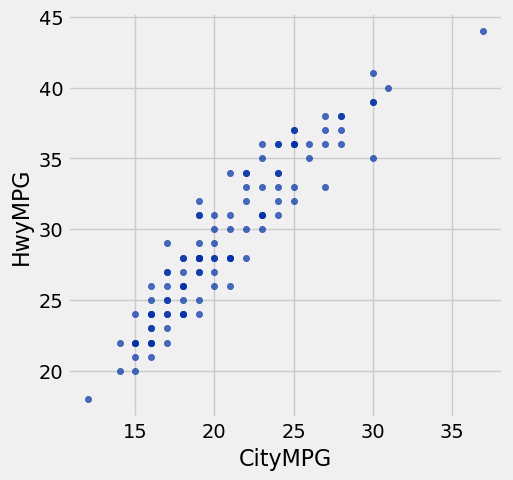

In [11]:
# example of a strong positive association
cars.scatter('CityMPG', 'HwyMPG')

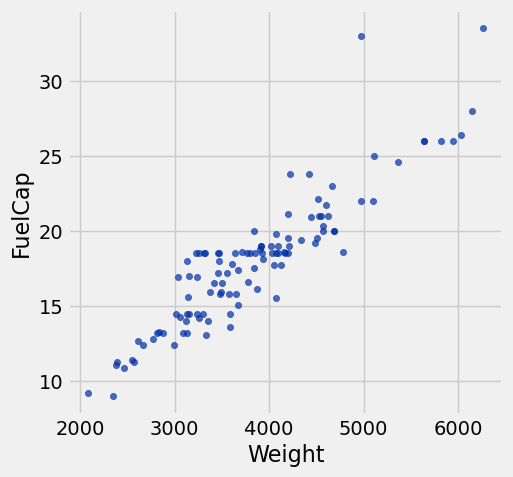

In [12]:
# example of a strong positive association
cars.scatter('Weight', 'FuelCap') 

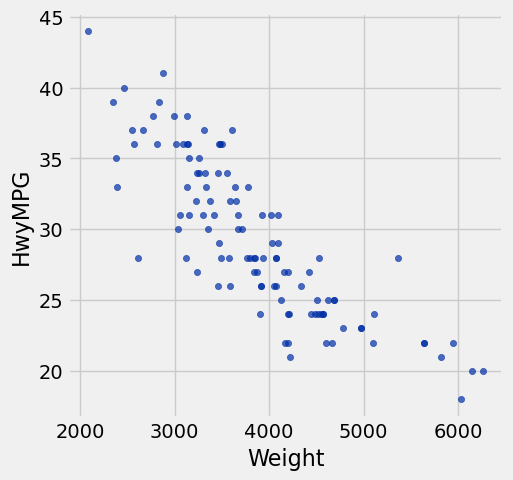

In [13]:
# example of a strong negative association
cars.scatter('Weight', 'HwyMPG')

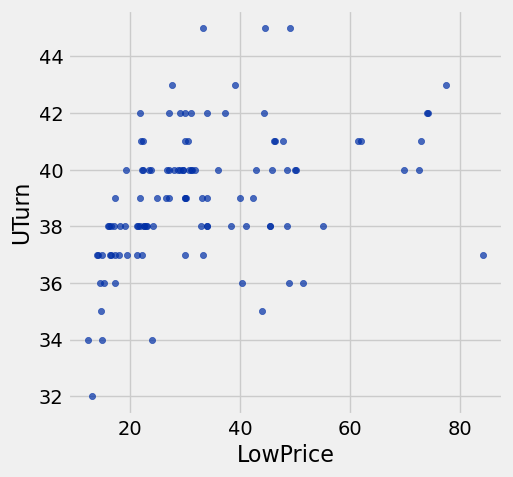

In [14]:
# weak positive association
cars.scatter('LowPrice', 'UTurn')

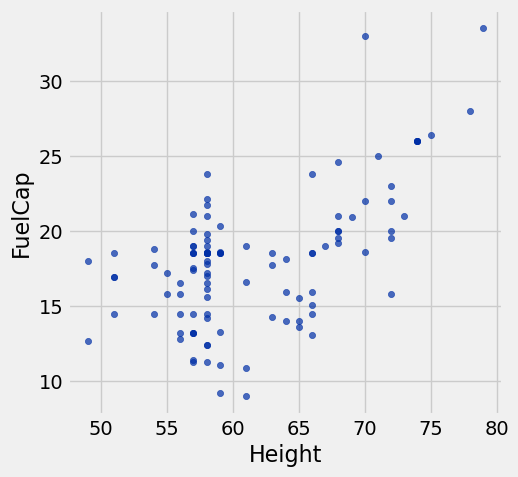

In [15]:
# weak positive association
cars.scatter('Height', 'FuelCap') 

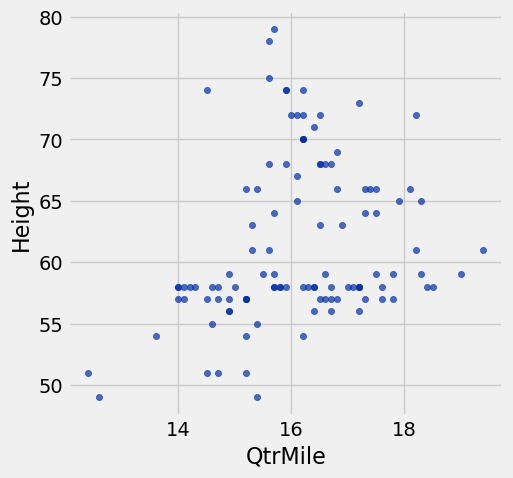

In [16]:
# almost no association
cars.scatter('QtrMile', 'Height') 

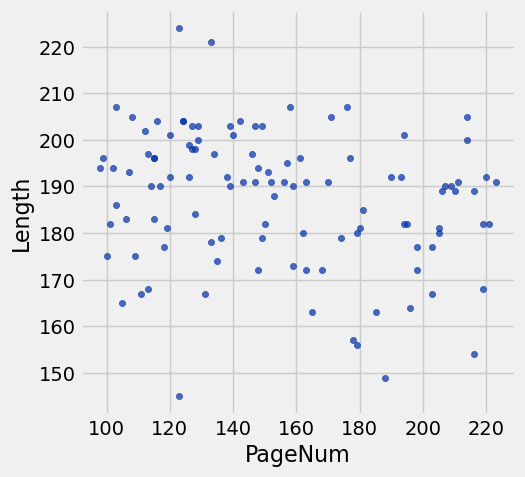

In [17]:
# no association
cars.scatter('PageNum', 'Length') 

### Convert to Standard Units

The quantity $z$ measures standard units, meaning the number of standard deviations above average.

To convert a value to standard units,
$$z = \frac{\text{value} - \text{average}}{\text{SD}}$$

As a result, all columns of numerical values are transformed to the same standard scale. The goal is to force a 0 mean and a 1 standard deviation for all the numerical arrays that we want to compare.

The x-axis and y-axis on a standard units plot represent the number of standard deviation.

By removing the original real-world units, we can focus on the values themselves without being distracted by their actual meanings (such as age, experience, salary etc). So we can clearly compare apples to apples on a fair standard scale.

In [18]:
# function to calculate standard units
def standard_units(numbers_array):
    "Convert any array of numbers to standard units."
    return (numbers_array - np.mean(numbers_array))/np.std(numbers_array)  

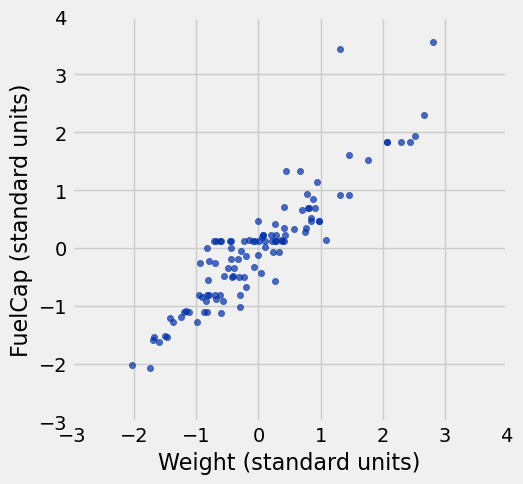

In [19]:
# convert to standard units
Table().with_columns(
    'Weight (standard units)', standard_units(cars.column('Weight')),
    'FuelCap (standard units)', standard_units(cars.column('FuelCap'))
).scatter(0, 1)
plots.xlim(-3, 4)
plots.ylim(-3, 4);

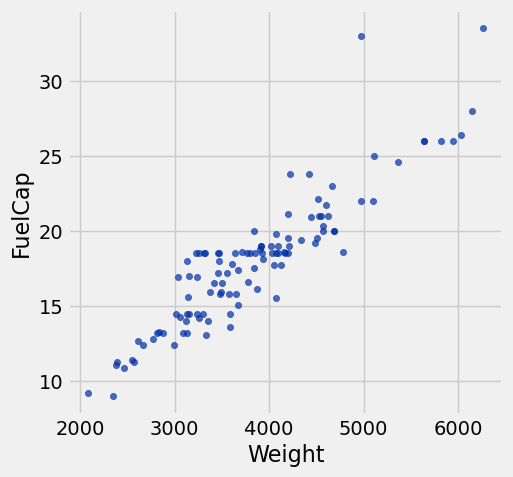

In [20]:
# take a look at the original real-world unit
cars.scatter('Weight', 'FuelCap')

### The Correlation Coefficient ($r$)

The correlation coefficient measures the strength of the linear relationship between two variables. Graphically, it measures how clustered the scatter diagram is around a straight line.

We call correlation coefficient $r$.

1. $r$ is a number between -1 and 1.
2. $r$ measures the extent to which the scatter plot clusters around a straight line.
3. $r = 1$ if the scatter diagram is a perfect straight line sloping upwards.
4. $r = -1$ if the scatter diagram is a perfect straight line sloping downwards.

#### How to calculate $r$?

$r$ is the average of the products of the two variables, when both variables are measured in **standard units**.

In [21]:
# step 1 - convert the variables (columns) to standard units
weight_fuelcap = cars.select('Weight', 'FuelCap')
weight_fuelcap_su = weight_fuelcap.with_columns(
    'Weight (standard units)', standard_units(cars.column('Weight')),
    'FuelCap (standard units)', standard_units(cars.column('FuelCap'))
)
weight_fuelcap_su.show(5)

Weight,FuelCap,Weight (standard units),FuelCap (standard units)
2345,9,-1.73819,-2.06797
2550,11.4,-1.50079,-1.51679
2575,11.3,-1.47184,-1.53975
2085,9.2,-2.03927,-2.02204
2470,10.9,-1.59343,-1.63162


In [22]:
# step 2 - multiply each pair of standard units
product_weight_fuelcap_su = weight_fuelcap_su.with_columns(
    'Product of standard units', weight_fuelcap_su.column(2) * weight_fuelcap_su.column(3)
)
product_weight_fuelcap_su

Weight,FuelCap,Weight (standard units),FuelCap (standard units),Product of standard units
2345,9,-1.73819,-2.06797,3.59451
2550,11.4,-1.50079,-1.51679,2.27638
2575,11.3,-1.47184,-1.53975,2.26627
2085,9.2,-2.03927,-2.02204,4.12348
2470,10.9,-1.59343,-1.63162,2.59987
3260,14.2,-0.678599,-0.873745,0.592923
3140,15.6,-0.817561,-0.552224,0.451477
3330,13.1,-0.597538,-1.12637,0.673048
2990,12.4,-0.991264,-1.28713,1.27589
2385,11.1,-1.69187,-1.58569,2.68277


In [23]:
# step 3 - r is the average of the produces computed in step 2
r = np.mean(product_weight_fuelcap_su.column(4))
r

0.91020298733780447

In [24]:
# let's create a function to calculate the r (Correlation Coefficient)
def correlation(table, label_x, label_y):
    return np.mean(standard_units(table.column(label_x))*standard_units(table.column(label_y)))

#### Check out $r$ on our dataset

In [25]:
correlation(cars, 'Height', 'FuelCap')

0.575958949157927

In [ ]:
correlation(cars, 'LowPrice', 'UTurn')

In [ ]:
correlation(cars, 'PageNum', 'Length')

In [ ]:
correlation(cars, 'Weight', 'HwyMPG')

In [ ]:
correlation(cars, 'CityMPG', 'HwyMPG')

### What Correlation Coefficient ($r$) can and cannot?

1. Correlation only measures association.
2. Correlation does not imply causation. (there may be confounding factors)
3. Correlation measures linear association (straight line).
4. Correlation is affected by outliers.

#### Example - non linear relation

Quadratic equation is a polynomial, the highest degree of power is 2.

The simplest form of a quadratic equation: $y = x^2$

##### Case 1: Positive and negative values

In [ ]:
x = make_array(-9, -8, -7, -6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9)
y = x ** 2
quadratic_1 = Table().with_columns('x', x, 'y', y)
quadratic_1.show()

In [ ]:
# we call this parabola
quadratic_1.scatter('x', 'y')

In [ ]:
# the mean of the positive and negative values cancel out and return 0
r = correlation(quadratic_1, 'x', 'y')
np.round(r, 2)

##### Case 2: Positive values only

In [ ]:
x = make_array(0, 1, 2, 3, 4, 5, 6, 7, 8, 9)
y = x ** 2
quadratic_2 = Table().with_columns('x', x, 'y', y)
quadratic_2

In [ ]:
quadratic_2.scatter('x', 'y')

In [ ]:
correlation(quadratic_2, 'x', 'y')

If a quadratic equation only contains positive values, the correlation ($r$) can be very close to 1.

##### Case 3: Negative values only

In [ ]:
x = make_array(-9, -8, -7, -6, -5, -4, -3, -2, -1, 0)
y = x ** 2
quadratic_3 = Table().with_columns('x', x, 'y', y)
quadratic_3

In [ ]:
quadratic_3.scatter('x', 'y')

In [ ]:
correlation(quadratic_3, 'x', 'y')

If a quadratic equation only contains negative values, the correlation ($r$) can be very close to -1.

We can still use linear regression and correlation $r$ to make predictions on a one-winged quadratic non linear dataset. 

#### Correlation is affected by outliers

There is an example on the textbook [15.1.7](https://inferentialthinking.com/chapters/15/1/correlation/#correlation-is-affected-by-outliers).

Outliers can have a big effect on correlation. Here is another example how outliers affect the $r$ (correlation coefficient).

In [ ]:
# dataset contains many outliers
salaries = Table.read_table('experience_vs_compensation.csv')
correlation(salaries, 'Experience_Years', 'Total_Compensation_USD')

In [ ]:
salaries.column('Experience_Years').max()

In [ ]:
salaries.scatter('Experience_Years', 'Total_Compensation_USD')

In [ ]:
# remove the oulliers
salaries_clean = salaries.where('Total_Compensation_USD', are.below(300001))
salaries_clean.scatter('Experience_Years', 'Total_Compensation_USD')

In [ ]:
correlation(salaries_clean, 'Experience_Years', 'Total_Compensation_USD')

**So, linear regression and correlation works best on a clean dataset without extreme outliers because the calculations rely on the mean and standard deviation values.**

#### Having a stronge correlation, we try to predict salaries based on years of experience

In [ ]:
def predict_salary(year):
    """ predict a salary based on +/- 1 year of experience """
    nearest_neighbors = salaries_clean.where('Experience_Years', are.between(year - 1, year + 1))
    return nearest_neighbors.column('Total_Compensation_USD').mean()   

In [ ]:
salaries_clean = salaries_clean.with_columns(
    'Average_Compensation', salaries_clean.apply(predict_salary, 'Experience_Years')
)

plots.scatter(salaries_clean.column('Experience_Years'), 
              salaries_clean.column('Total_Compensation_USD'),
              color='blue', alpha=0.5)
plots.scatter(salaries_clean.column('Experience_Years'), 
              salaries_clean.column('Average_Compensation'),
              color='red', alpha=0.5)

In [ ]:
salaries_clean

In [ ]:
# convert to standard units
salaries_clean_su = salaries_clean.with_columns(
    'Years_SU_z', standard_units(salaries_clean.column('Experience_Years')), 
    'Comp_SU_z', standard_units(salaries_clean.column('Total_Compensation_USD'))
)
salaries_clean_su.show(5)

In [ ]:
# number of years in 1 SD
sd_experience_years = np.std(salaries_clean.column('Experience_Years'))
sd_experience_years

In [ ]:
# 1 year of SD
1 / sd_experience_years

In [ ]:
# predict salary in standard units
def predict_salary_su(year_su):
    """ predict a salary based on standard units """
    nearest = 1.0 / np.std(salaries_clean.column('Experience_Years'))
    nearest_neighbors = salaries_clean_su.where('Years_SU_z', are.between(year_su - nearest, year_su + nearest))
    return nearest_neighbors.column('Comp_SU_z').mean()  

In [ ]:
# use tbl.apply() to call the function
predicted_salaries_su = salaries_clean_su.apply(predict_salary_su, 'Years_SU_z')

salaries_clean_su = salaries_clean_su.with_columns('Average_Comp_SU_z', predicted_salaries_su)
salaries_clean_su.show(5)

In [ ]:
salaries_clean_su.where('Experience_Years', 3)

In [ ]:
# overlay the prediction in standard units
# overlay the prediction
plots.scatter(salaries_clean_su.column('Years_SU_z'), 
              salaries_clean_su.column('Comp_SU_z'),
              color='blue', alpha=0.5)
plots.scatter(salaries_clean_su.column('Years_SU_z'), 
              salaries_clean_su.column('Average_Comp_SU_z'),
              color='red', alpha=0.5)

What we have just done above is called **nearest neighborhood regression**. The scatter plots (red dotted line) we drew is **call graph of averages**.

### Check out datasets with different correlation coefficient ($r$)

The salaries example has very stronge association ($r > 0.9$). Remember, $-1 <= r <= 1$

Let's take a look at how datasets look like with different $r$.

In [26]:
# nearest neighbors function
def nearest_neighbor_prediction(x_val):
    """ Predicts y-value for x based on the table named example """
    neighbors = example.where('x', are.between(x_val - 1/2, x_val + 1/2))
    return np.mean(neighbors.column('y'))

0.0027099363484845984

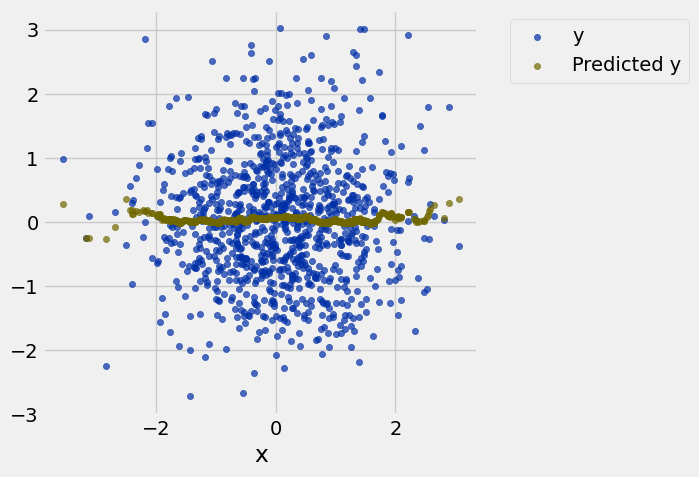

In [27]:
example = r_table(0)
example = example.with_column('Predicted y', example.apply(nearest_neighbor_prediction, 'x'))
example.scatter('x')
correlation(example, 'x', 'y')

0.51527804629589546

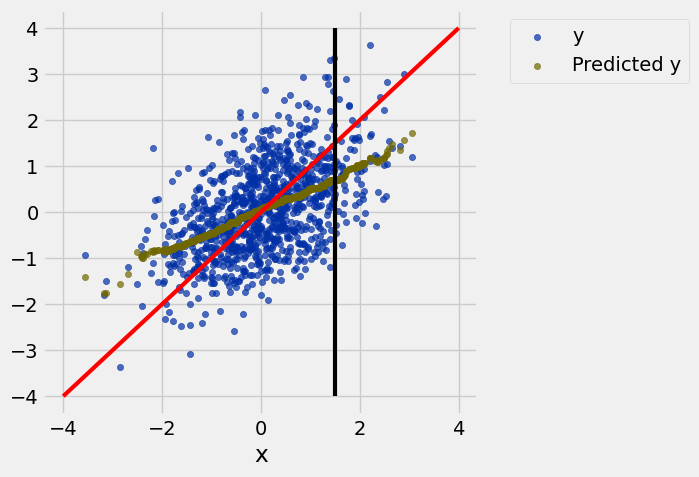

In [28]:
example = r_table(0.5)
example = example.with_column('Predicted y', example.apply(nearest_neighbor_prediction, 'x'))
example.scatter('x')
draw_line(slope=1, color='red')
draw_vertical_line(1.5)
correlation(example, 'x', 'y')

In [ ]:
example = r_table(0.94)
example = example.with_column('Predicted y', example.apply(nearest_neighbor_prediction, 'x'))
example.scatter('x')
draw_line(slope=1, color='red')
correlation(example, 'x', 'y')

The red line is at $45^\circ$ and its $r$ (correlation coefficient) is 1. But it doesn't align with the graph of averages. That means when we draw a vertical line across the x-axis, the intercept of the $45^\circ$ red line and the vertical line may not meet at the average point of the vertical line across.

### Regression Line

The regression line is a smoothed out straight line approximation of graph of averages.

"In regression, we use the value of one variable (which we will call $x$) to predict the value of another (which we will call $y$). When the variables $x$ and $y$ are measured in standard units, the regression line for predicting $y$ based on $x$ has slope $r$ and passes through the origin."

**Correlation Coefficient ($r$)** is the average of the products of the two variables, when both variables are measured in **standard units**.

The regression equation requires two parameters: **slope fo the regression line ($m$)** and **intercept of the regression line ($b$)**.

The formulas for computing the slope and intercept are both based on the correlation coefficient $r$ computed above: 

$$m = r \cdot \frac{SD_y}{SD_x}$$

$$b = \bar{y} - m\bar{x}$$

where $\bar{y}$ and $\bar{x}$ are the means of x and y values, respectively. $SD$ is standard deviation.

So, when we predict $\bar{y}$ based on $\bar{x}$,

$$\bar{y} = m\bar{x} + b$$

We need three function to calculate the $r$ (correlation), the $m$ (slope) and the $b$ (intercept).


In [ ]:
def correlation(table, label_x, label_y):
    return np.mean(standard_units(table.column(label_x))*standard_units(table.column(label_y)))

def slope(table, label_x, label_y):
    r = correlation(table, label_x, label_y)
    return r*np.std(table.column(label_y))/np.std(table.column(label_x))

def intercept(table, label_x, label_y):
    return np.mean(table.column(label_y)) - slope(table, label_x, label_y)*np.mean(table.column(label_x))

### The Regression Line in the Units of the Data (Salaries Example)

In [ ]:
salary_r = correlation(salaries_clean_su, 'Experience_Years', 'Total_Compensation_USD')
salary_slope = slope(salaries_clean_su, 'Experience_Years', 'Total_Compensation_USD')
salary_intercept = intercept(salaries_clean_su, 'Experience_Years', 'Total_Compensation_USD')
print(f"correlation: {salary_r}, slope: {salary_slope}, intercept: {salary_intercept}")

In [ ]:
salary_slope * 6.8 + salary_intercept

In [ ]:
salaries_clean_su = salaries_clean_su.with_column(
    'Regression_Prediction', 
    salary_slope * salaries_clean_su.column('Experience_Years') + salary_intercept
)
salaries_tbl = salaries_clean_su.select('Experience_Years', 'Total_Compensation_USD', 'Average_Compensation', 'Regression_Prediction')
salaries_tbl.where('Experience_Years', are.between(6, 8))

In [ ]:
plots.scatter(salaries_clean_su.column('Experience_Years'), 
              salaries_clean_su.column('Total_Compensation_USD'),
              color='blue', alpha=0.5)
plots.scatter(salaries_clean_su.column('Experience_Years'), 
              salaries_clean_su.column('Average_Compensation'),
              color='red', alpha=0.5)
plots.scatter(salaries_clean_su.column('Experience_Years'), 
              salaries_clean_su.column('Regression_Prediction'),
              color='yellow', alpha=0.5)

The yellow dots show the regression predictions, all on the regression line. Notice how the line is very close to the red graph of averages. 

In [ ]:
years = np.arange(0, 21, 0.5)

regression_prediction = Table().with_columns(
    'Years', years,
    'Regression_Prediction', salary_slope * years + salary_intercept,
)

regression_prediction

In [ ]:
salaries_tbl.where('Experience_Years', 3)

In [ ]:
# function to calculate the regression line
def fit(table, x, y):
    """Return the height of the regression line at each x value."""
    a = slope(table, x, y)
    b = intercept(table, x, y)
    return a * table.column(x) + b

### The Method of Least Squares

"**The regression line is the unique straight line that minimizes the mean squared error of estimation among all straight lines.**"

The regression line is the only line that minimizes mean squared error. Regression line is sometimes called the “least squares line.”

#### Error in Estimation

<img src="rmse-a.png" alt="Root mean squared error" width=350/>
<img src="rmse-b.png" alt="Root mean squared error" width=350/>
<img src="rmse-c.png" alt="Root mean squared error" width=350/>

#### Regression equation:
$\bar{y} = m\bar{x} + b$
where $m$ is slope and $b$ is intercept.

#### Mean Squared Error (MSE)
$np.mean((y - \bar{y})^2)$

#### Minimizing the Root Mean Squared Error

The mean squared error (MSE) of estimation is a measure of roughly how big the squared errors are. But the result is very big because the mean is equared. So by taking a square root, we call it Root Mean Square Error (RMSE).

$np.sqrt(np.mean((y - \bar{y})^2))$

- To get estimates of $y$ based on $x$, you can use any line you want.
- Every line has a root mean squared error of estimation.
- “Better” lines have smaller errors.

So, we can create a function to calculate the MSE.

In [ ]:
cars.scatter('FuelCap', 'Weight') 

In [ ]:
def cars_mse(any_slope, any_intercept):
    x = cars.column('FuelCap')
    y = cars.column('Weight')
    fitted = any_slope*x + any_intercept
    #plots.scatter(x, y)
    #plots.scatter(x, fitted)
    return np.mean((y - fitted) ** 2)

In [ ]:
cars_slope = slope(cars, 'FuelCap', 'Weight')
cars_intercept = intercept(cars, 'FuelCap', 'Weight')
# return the least square error
cars_mse(cars_slope, cars_intercept)**0.5

In [ ]:
# return the slope and intercept that produces the least square error
minimize(cars_mse)

In [ ]:
best_result = minimize(cars_mse)
cars_slope = best_result.item(0)
cars_intercept = best_result.item(1)
(cars_slope, cars_intercept)

In [ ]:
fitted = fit(cars, 'FuelCap', 'Weight')
cars.select('FuelCap', 'Weight').with_columns('Best Straight Line', fitted).scatter('FuelCap')

x = cars.column('FuelCap')
x_ends = make_array(min(x), max(x))
y_ends = (cars_slope * x_ends) + cars_intercept
#cars.scatter('FuelCap', 'Weight')
plots.plot(x_ends, y_ends, color='purple', alpha=0.2)

In [ ]:
def mse_for_all(table, x_label, y_label):
    x_data = table.column(x_label)
    y_data = table.column(y_label)
    
    def mse_function(slope, intercept):
        fitted = (slope * x_data) + intercept
        return np.mean((y_data - fitted) ** 2)
    
    return mse_function

In [ ]:
fitted = fit(cars, 'HwyMPG', 'Weight')
cars.select('HwyMPG', 'Weight').with_columns('Best Straight Line', fitted).scatter('HwyMPG')

hwympg_weight_mse = mse_for_all(cars, 'HwyMPG', 'Weight')
best_result = minimize(hwympg_weight_mse)
x = cars.column('HwyMPG')
x_ends = make_array(min(x), max(x))
y_ends = (best_result.item(0) * x_ends) + best_result.item(1)
#cars.scatter('HwyMPG', 'Weight')
plots.plot(x_ends, y_ends, color='purple', alpha=0.3)

In [ ]:
fitted = fit(cars, 'FuelCap', 'Height')
cars.select('FuelCap', 'Height').with_columns('Best Straight Line', fitted).scatter('FuelCap')

fuelcap_height_mse = mse_for_all(cars, 'FuelCap', 'Height')
best_result = minimize(fuelcap_height_mse)
x = cars.column('FuelCap')
x_ends = make_array(min(x), max(x))
y_ends = (best_result.item(0) * x_ends) + best_result.item(1)
#cars.scatter('FuelCap', 'Height')
plots.plot(x_ends, y_ends, color='purple', alpha=0.3)

### 

### Nonlinear Regression

$$f(x) = ax^2 + bx + c$$
for constants $a$, $b$, and $c$.

In [ ]:
shotput = Table.read_table('shotput.csv')

In [ ]:
def shotput_quadratic_mse(a, b, c):
    x = shotput.column('Weight Lifted')
    y = shotput.column('Shot Put Distance')
    fitted = a*(x**2) + b*x + c
    return np.mean((y - fitted) ** 2)

In [ ]:
best = minimize(shotput_quadratic_mse)
best

In [ ]:
(-0.00104)*(100**2) + 0.2827*100 - 1.5318

In [ ]:
x = shotput.column(0)
shotput_fit = best.item(0)*(x**2) + best.item(1)*x + best.item(2)

In [ ]:
shotput.with_column('Best Quadratic Curve', shotput_fit).scatter(0)

#xlimits = np.arange(35, 150, 10)
#plots.plot(xlimits, best.item(0)*xlimits**2 + best.item(1)*xlimits + best.item(2),color='purple', alpha=0.3)